In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
peng = pd.read_csv('../../data/penguins.csv').dropna()
planets = pd.read_csv('../../data/PlanetsData.csv').dropna()
print(peng.head())
print(planets.head())

  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
4  Adelie  Torgersen            36.7           19.3              193.0   
5  Adelie  Torgersen            39.3           20.6              190.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
4       3450.0  female  2007  
5       3650.0    male  2007  
    planet  distance  diameter  revolution  position
0  Mercury        36      3030          88         1
1    Venus        67      7520         225         2
2    Earth        93      7926         365         3
3     Mars       142      4217         687         4
4  Jupiter       484     88838        4332         5


### 1a)

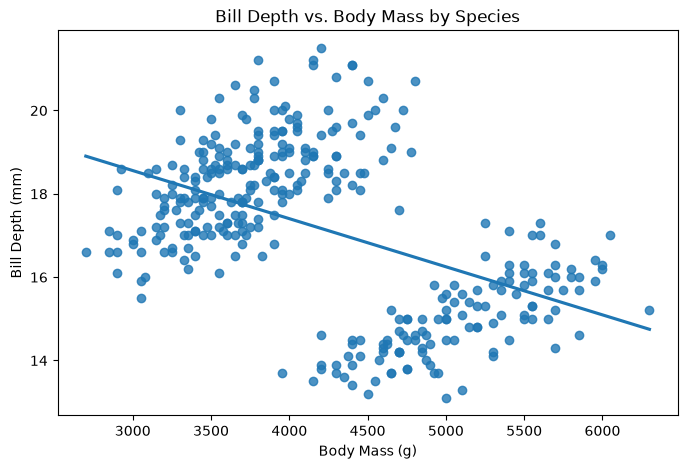

In [3]:
plt.figure(figsize=(8, 5))
sns.regplot(data=peng, x='body_mass_g', y='bill_depth_mm', ci=False)
plt.title('Bill Depth vs. Body Mass by Species')
plt.xlabel('Body Mass (g)')
plt.ylabel('Bill Depth (mm)')
plt.show()

The plot seems to show 2 distinct groups, likely separated by species. The relationship as a whole is weakly negative, and isn't what I'd expect. I'd generally expect a larger penguin to have a deeper bill (which is shown if the groups are separated)

### 1b)

In [4]:
x = peng['bill_depth_mm']
y = peng['body_mass_g']

m = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
b = y.mean() - m * x.mean()

print(f"Here is the estimated regression equation: y = {b:.3f} + X_1 * ({m:.3f})")

Here is the estimated regression equation: y = 7519.981 + X_1 * (-193.006)


For every mm increase in bill depth, the model estimates that the average penguin will weigh about 191 grams less.

### 1c)

In [5]:
y_hat = b + (m * x)
residuals = y - y_hat
n = len(y)

rse = np.sqrt(np.sum(residuals**2) / (n - 2))
r = np.corrcoef(x, y)[0, 1]
r2 = r**2

print(f"RSE: {rse:.3f} \nR squared: {r2:.3f}")

RSE: 710.942 
R squared: 0.223


The high RSE indicates that the model does not fit the data very well, and the low $r^2$ indicates that the model does not explain much of the variance seen.

### 2a) 

In [9]:
model = smf.ols('body_mass_g ~ bill_depth_mm', data=peng).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.223
Model:                            OLS   Adj. R-squared:                  0.220
Method:                 Least Squares   F-statistic:                     94.89
Date:                Sun, 13 Sep 2026   Prob (F-statistic):           7.02e-20
Time:                        11:58:48   Log-Likelihood:                -2658.2
No. Observations:                 333   AIC:                             5320.
Df Residuals:                     331   BIC:                             5328.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      7519.9808    342.325     21.967

- $H_0$ = There is no relationship between bill depth and body mass among the penguins
- $H_1$ = There is a relationship between bill depth and body mass
- The $B_1$ is -193.01 with a standard error of 19.81, t statistic of -9.74, and p value of 0.

### 2b) 

- $R^2$: The r squared measures the variance in penguin mass explained by bill depth. It is fairly small with an adj. r squared of .220
- The p value measures the probability that the relationship between weight and bill depth is not 0. Since the p value is 0, we are extremely confident that there is a significant relationship between bill depth and body mass
- So there definitely is a relationship between bill depth and mass, but it is not the strongest linear predictor according to the $R^2$

### 2c)

In [10]:
np.random.seed(6021)
n = 10000
boot_b0 = []
boot_b1 = []

for num in range(n):
    sample = peng.sample(frac=1.0, replace=True)
    #ai helped with syntax on b1
    b1 = np.cov(sample['bill_depth_mm'], sample['body_mass_g'])[0, 1] / np.var(sample['bill_depth_mm'], ddof=1)
    b0 = sample['body_mass_g'].mean() - b1 * sample['bill_depth_mm'].mean()
    boot_b0.append(b0)
    boot_b1.append(b1)

ci_b0 = np.percentile(boot_b0, [2.5, 97.5])
ci_b1 = np.percentile(boot_b1, [2.5, 97.5])

In [11]:
print(f"The confidence interval for Beta 0 is ({ci_b0[0]:.2f}, {ci_b0[1]:.2f})")
print(f"The confidence interval for Beta 1 is ({ci_b1[0]:.2f}, {ci_b1[1]:.2f})")

The confidence interval for Beta 0 is (6982.87, 8086.70)
The confidence interval for Beta 1 is (-225.24, -162.86)


### 2.c.a) 
The bootstrapping method gave a slightly tighter confidence interval for the coefficient estimate. Maybe the sample data has a tighter spread than what statsmodels assumes? I'm not too sure what it's telling us since the intervals are pretty similar.

### 2.c.b)
It assumes constant variance and normally distributed residuals

### 2.c.c and 2.c.d)


In [ ]:
B_values = [100, 1000, 10000]
num_trials = 10
results_list = []

#gemini helped with the structure of the loops
#The results are consistent with what I'd expect them to be
for B in B_values:
    for trial in range(1, num_trials + 1):
        np.random.seed()
        boot_b0 = np.empty(B)
        boot_b1 = np.empty(B)
        n_samples = len(peng)
        for i in range(B):
            sample = peng.sample(n=n_samples, replace=True)
            x = sample["bill_depth_mm"].values
            y = sample["body_mass_g"].values
            b1 = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
            b0 = np.mean(y) - b1 * np.mean(x)
            boot_b0[i] = b0
            boot_b1[i] = b1

        b0_p2_5, b0_p97_5 = np.percentile(boot_b0, [2.5, 97.5])
        b1_p2_5, b1_p97_5 = np.percentile(boot_b1, [2.5, 97.5])

        results_list.append(
            {
                "B": B,
                "Trial": trial,
                "beta0_2.5%": b0_p2_5,
                "beta0_97.5%": b0_p97_5,
                "beta0_CI_Width": b0_p97_5 - b0_p2_5,
                "beta1_2.5%": b1_p2_5,
                "beta1_97.5%": b1_p97_5,
                "beta1_CI_Width": b1_p97_5 - b1_p2_5,
            }
        )

df_bootstrap_comparison = pd.DataFrame(results_list)

print(df_bootstrap_comparison)

        B  Trial   beta0_2.5%  beta0_97.5%  beta0_CI_Width  beta1_2.5%  \
0     100      1  6978.095058  8071.801860     1093.706802 -223.828881   
1     100      2  6923.773534  8033.111446     1109.337912 -222.190290   
2     100      3  6959.322347  8025.193439     1065.871093 -221.662484   
3     100      4  6996.191406  8161.562064     1165.370658 -229.497692   
4     100      5  6955.691995  8048.203040     1092.511045 -222.409362   
5     100      6  6992.887034  8001.282698     1008.395664 -217.234836   
6     100      7  7019.298055  8148.013581     1128.715527 -229.849525   
7     100      8  7030.899334  7947.220059      916.320724 -217.474636   
8     100      9  6995.648706  8252.421043     1256.772337 -234.125669   
9     100     10  6940.722663  7970.251790     1029.529127 -218.161948   
10   1000      1  7013.212958  8107.509581     1094.296623 -226.245423   
11   1000      2  6952.073804  8083.708905     1131.635101 -224.529767   
12   1000      3  6986.369791  8076.58

In [13]:
summary_tb = df_bootstrap_comparison.groupby("B")[
    ["beta0_2.5%", "beta0_97.5%", "beta1_2.5%", "beta1_97.5%"]].agg(["mean", "std"])
print(summary_tb)

        beta0_2.5%             beta0_97.5%             beta1_2.5%            \
              mean        std         mean        std        mean       std   
B                                                                             
100    6979.253013  34.203341  8065.906102  94.969587 -223.643532  5.768007   
1000   6977.521466  20.802588  8082.261260  22.430682 -225.021520  1.433121   
10000  6975.529041   5.266167  8088.324189   7.641783 -225.222235  0.443404   

      beta1_97.5%            
             mean       std  
B                            
100   -162.618041  2.450327  
1000  -162.805835  1.319370  
10000 -162.693956  0.269808  


With the smaller number of bootstraps (n=100), the standard deviation on the B1 estimates are much larger (94.9) than the standard deviation than the larger sample sizes (7.6). This allows us to be more confident in the range where a more accurate B1 lies.

### 3a)

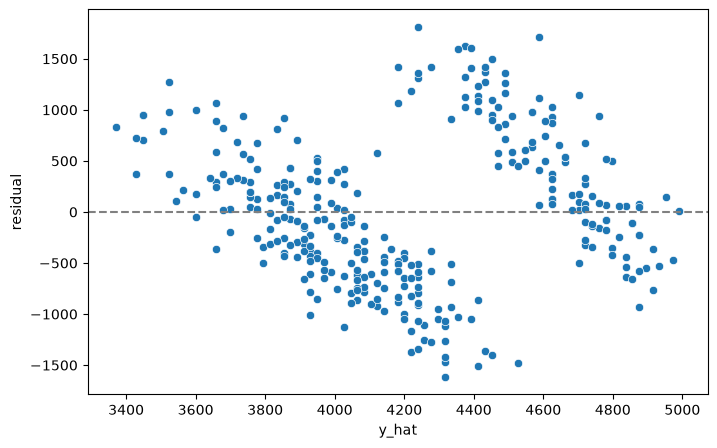

In [14]:
peng['y_hat'] = model.predict()
peng['residual'] = model.resid

plt.figure(figsize=(8, 5))
sns.scatterplot(data=peng, x='y_hat', y='residual')
plt.axhline(0, color='gray', linestyle='--')

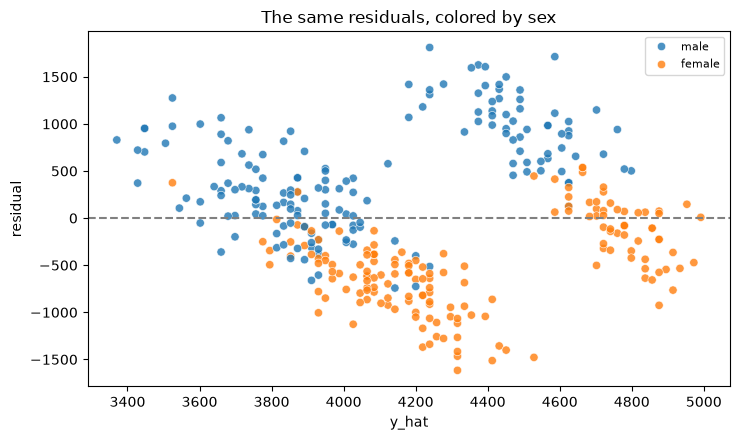

In [15]:
# class plot
plt.figure(figsize=(7.5, 4.5))
ax = sns.scatterplot(data=peng.dropna(subset=["sex"]), x="y_hat", y="residual",
                     hue="sex", alpha=0.8)
ax.axhline(0, color="gray", ls="--")
ax.set_title("The same residuals, colored by sex")
ax.legend(fontsize=8)
plt.tight_layout()

These plots are telling me correlation among the error term. My guess is that fitting the model on all 3 species without accounting for them as a variable creates bias and that's shown in the residual plot

### 3b)

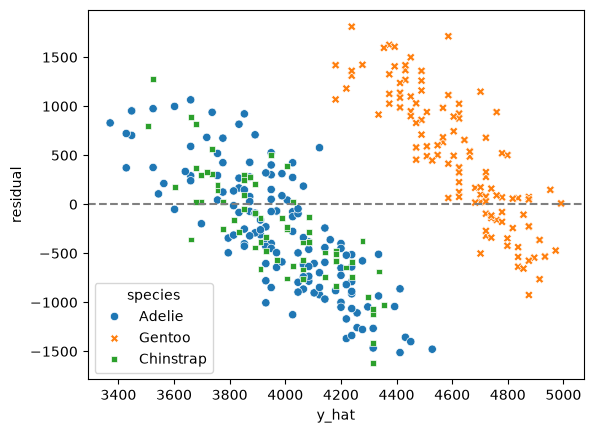

In [16]:
peng['y_hat'] = model.predict()
peng['residual'] = model.resid

sns.scatterplot(data=peng, x='y_hat', y='residual', hue='species', style='species')
plt.axhline(0, color='gray', linestyle='--')

Yup, Gentoo penguins are much heavier than predicted since they appear to be a large bird with a shallow bill. Since the model was trained on all 3 species and doesn't account for it as a variable, the heteroskedasticity appears to be influenced by the species of the penguin

### 3c)

In [17]:
print(peng[['bill_depth_mm', 'body_mass_g']].corr().iloc[0, 1]) #all species

-0.4720156601951403


In [18]:
peng.groupby('species')[['bill_depth_mm', 'body_mass_g']].corr().iloc[0::2, 1]

species                 
Adelie     bill_depth_mm    0.580156
Chinstrap  bill_depth_mm    0.604498
Gentoo     bill_depth_mm    0.722967
Name: body_mass_g, dtype: float64

Because there are 2 distinct groups that form a sort of downward slope, that causes the correlation between bill depth and mass to be negative. Once species is accounted for, though, all of the correlations are positive because they aren't dealing with the different characteristics of other penguin species.

In [19]:
adelie = peng.loc[peng['species'] == 'Adelie']
adelie_model = sm.OLS(adelie['body_mass_g'], adelie['bill_depth_mm']).fit()
print(adelie_model.summary())

                                 OLS Regression Results                                
Dep. Variable:            body_mass_g   R-squared (uncentered):                   0.990
Model:                            OLS   Adj. R-squared (uncentered):              0.990
Method:                 Least Squares   F-statistic:                          1.440e+04
Date:                Sun, 13 Sep 2026   Prob (F-statistic):                   5.19e-147
Time:                        12:15:11   Log-Likelihood:                         -1071.6
No. Observations:                 146   AIC:                                      2145.
Df Residuals:                     145   BIC:                                      2148.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

<Axes: xlabel='bill_depth_mm', ylabel='body_mass_g'>

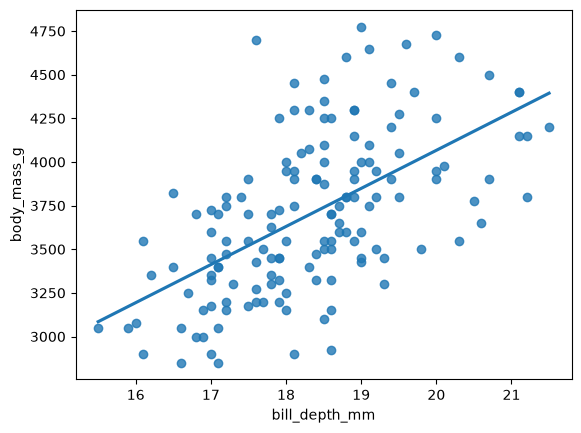

In [20]:
sns.regplot(data=adelie, x='bill_depth_mm', y='body_mass_g', ci=False)

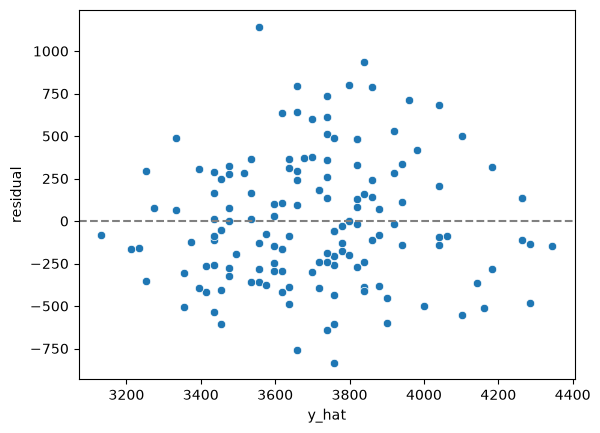

In [21]:
adelie['y_hat'] = adelie_model.predict()
adelie['residual'] = adelie_model.resid
sns.scatterplot(data=adelie, x='y_hat', y='residual')
plt.axhline(0, color='gray', linestyle='--')

Here the error terms are much more normally distributed and the positive correlation between bill depth and body mass is much easier to see when the model is built on just one species. I think this shows how important it is to ensure the model is built on similar data that it's trying to predict, or include those differences as variables in the model so it can account for them (such as species)

### 4a) 

The adjusted $R^2$ will always be the same or less than the regular $R^2$. This is due to the fact that the adjusted $R^2$ takes into account the degrees of freedom/number of model parameters. If you continue to add more parameters to the model, it will become overfit and its explained sum of squares will be higher, making $R^2$ higher. This is why adjusted $R^2$ takes into account the degrees of freedom, so it can marginally fight back against overfitting a model.

### 4b)

In [22]:
cols = ['body_mass_g', 'flipper_length_mm', 'bill_depth_mm', 'bill_length_mm']
peng_clean = peng[cols]

m1 = smf.ols('body_mass_g ~ flipper_length_mm', data=peng_clean).fit()
m2 = smf.ols('body_mass_g ~ flipper_length_mm + bill_depth_mm', data=peng_clean).fit()
m3 = smf.ols('body_mass_g ~ flipper_length_mm + bill_depth_mm + bill_length_mm', data=peng_clean).fit()

model_comp = pd.DataFrame({
    'Model': [1, 2, 3],
    'Predictors': ['flipper', 'flipper + depth', 'flipper + depth + length'],
    'R-squared': [m1.rsquared, m2.rsquared, m3.rsquared],
    'Adj R-squared': [m1.rsquared_adj, m2.rsquared_adj, m3.rsquared_adj],
    'RSE': [np.sqrt(m1.mse_resid), np.sqrt(m2.mse_resid), np.sqrt(m3.mse_resid)],
    'F-Statistic': [m1.fvalue, m2.fvalue, m3.fvalue]
})
model_comp

,Model,Predictors,R-squared,Adj R-squared,RSE,F-Statistic
0,1,flipper,0.762092,0.761373,393.343261,1060.295034
1,2,flipper + depth,0.763666,0.762234,392.633206,533.165867
2,3,flipper + depth + length,0.763937,0.761784,393.004605,354.897950


I would choose model 2 since it has the highest adjusted $R^2$. For model 3 I was concerned about including both bill depth and length becasue I feel like those would be correlated and introduce multicollinearity

### 4c)

In [23]:
print(m2.params)

Intercept           -6537.597784
flipper_length_mm      51.766973
bill_depth_mm          19.878001
dtype: float64


- In Model 2, when controlling for flipper length, the coefficient on bill_depth_mm becomes positive.
- Holding flipper length constant, a 1 mm increase in bill depth is expected to add 22.63 grams of mass in the average penguin

### 4c)
- Null Hypothesis $H_0$: None of the predictors have a nonzero linear relationship with body mass
- Alternative Hypothesis $H_1$: At least one coefficient has a nonzero linear relationship with body mass
- Conclusion: Because the F statistic is very large, we reject the null hypothesis and conclude that at least one variable in model 3 has a nonzero linear relationship with body mass

### 5a)

In [24]:
planets.head()

,planet,distance,diameter,revolution,position,predicted_revolution
0,Mercury,36,3030,88,1,-3711.348645
1,Venus,67,7520,225,2,-2964.382280
2,Earth,93,7926,365,3,-2337.894361
3,Mars,142,4217,687,4,-1157.205590
4,Jupiter,484,88838,4332,5,7083.520113


In [25]:
m_planets_lin = smf.ols('revolution ~ distance', data=planets).fit()
print(m_planets_lin.summary())

planets['predicted_revolution'] = m_planets_lin.predict(planets['distance'])
compare = planets[['planet', 'distance', 'revolution', 'predicted_revolution']].copy()
compare['residual'] = compare['revolution'] - compare['predicted_revolution']

compare

                            OLS Regression Results                            
Dep. Variable:             revolution   R-squared:                       0.978
Model:                            OLS   Adj. R-squared:                  0.975
Method:                 Least Squares   F-statistic:                     312.1
Date:                Sun, 13 Sep 2026   Prob (F-statistic):           4.59e-07
Time:                        12:16:32   Log-Likelihood:                -88.599
No. Observations:                   9   AIC:                             181.2
Df Residuals:                       7   BIC:                             181.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -4578.7935   2287.376     -2.002      0.0

,planet,distance,revolution,predicted_revolution,residual
0,Mercury,36,88,-3711.348645,3799.348645
1,Venus,67,225,-2964.382280,3189.382280
2,Earth,93,365,-2337.894361,2702.894361
3,Mars,142,687,-1157.205590,1844.205590
4,Jupiter,484,4332,7083.520113,-2751.520113
5,Saturn,887,10760,16794.082858,-6034.082858
6,Uranus,1765,30684,37950.097969,-7266.097969
7,Neptune,2791,60188,62672.275081,-2484.275081
8,Pluto,3654,90467,83466.854854,7000.145146


The model predicted negative revolutions for the 4 innermost planets and the residual was positive for all of them. 

### 5b)

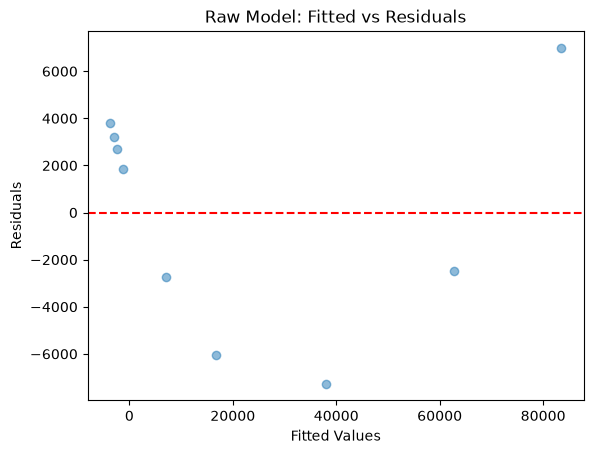

In [26]:
plt.scatter(m_planets_lin.fittedvalues, m_planets_lin.resid, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.title('Raw Model: Fitted vs Residuals')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.show()

Every planet has a large residual, but the largest are Saturn, Uranus, and Pluto in a parabolic shape. This suggests that the relationship between revolutions and distance is not linear.

### 5c)

                            OLS Regression Results                            
Dep. Variable:                log_rev   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 1.585e+06
Date:                Sun, 13 Sep 2026   Prob (F-statistic):           5.26e-20
Time:                        12:17:22   Log-Likelihood:                 34.696
No. Observations:                   9   AIC:                            -65.39
Df Residuals:                       7   BIC:                            -65.00
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.9031      0.007   -122.147   

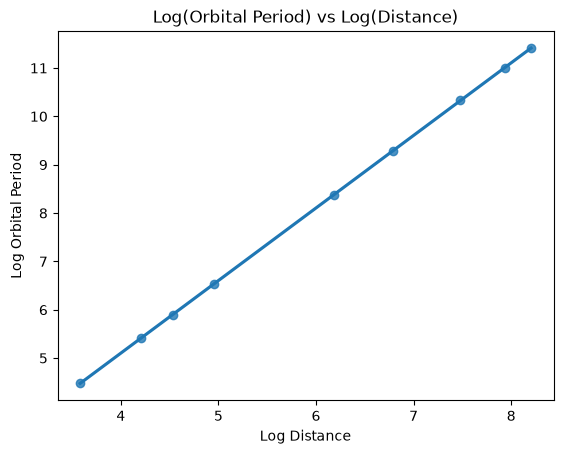

In [27]:
planets['log_rev'] = np.log(planets['revolution'])
planets['log_distance'] = np.log(planets['distance'])

m_planets_log = smf.ols('log_rev ~ log_distance', data=planets).fit()
print(m_planets_log.summary())

sns.regplot(data=planets, x='log_distance', y='log_rev')
plt.title('Log(Orbital Period) vs Log(Distance)')
plt.xlabel('Log Distance')
plt.ylabel('Log Orbital Period')
plt.show()

In [28]:
print(f"Log Model Rsq: {m_planets_log.rsquared:.4f}")

Log Model Rsq: 1.0000


The new $R^2$ is 1 and the estimated slope is 1.5013, or ~ $3/2$. Taking the logs of both distance and revolution period made the model nearly perfect, showing Kepler's third law.

In [29]:
planets['pred_log_rev'] = m_planets_log.predict()
planets['pred_rev_original_scale'] = np.exp(planets['pred_log_rev'])

comparison_log_df = planets[['distance', 'revolution', 'pred_rev_original_scale']].copy()
comparison_log_df

,distance,revolution,pred_rev_original_scale
0,36,88,87.955672
1,67,225,223.498426
2,93,365,365.655904
3,142,687,690.272590
4,484,4332,4350.622150
5,887,10760,10802.199220
6,1765,30684,30348.267640
7,2791,60188,60383.237531
8,3654,90467,90486.168764


The actual vs predicted are almost spot on, pretty much proving Kepler's third law.